# Machine Learning Project — USA Housing Price Prediction

## Task 1: Dataset Selection
Dataset: USA_Housing.csv from Kaggle
Source: https://www.kaggle.com/datasets/vedavyasv/usa-housing
The dataset contains 5000 rows and 7 columns with information about houses in the USA.
The target variable is 'Price' which is a continuous numerical value, making it suitable for a Linear Regression model.

## Task 2: Problem Definition
Problem: Predict the price of a house based on its features.
Type of Problem: Regression (predicting a continuous number)
Input Features: Avg. Area Income, Avg. Area House Age, Avg. Area Number of Rooms, Avg. Area Number of Bedrooms, Area Population
Target Variable: Price

## Task 3: Data Loading & Understanding

In [2]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
# Load the dataset
df = pd.read_csv('USA_Housing.csv')
# Display first few rows
print("First 5 rows:")
df.head()

First 5 rows:


,Avg. Area Income,Avg. Area House Age,Avg. Area Number of Rooms,Avg. Area Number of Bedrooms,Area Population,Price,Address
0,79545.458574,5.682861,7.009188,4.09,23086.800503,1.059034e+06,"208 Michael Ferry Apt. 674\nLaurabury, NE 3701..."
1,79248.642455,6.002900,6.730821,3.09,40173.072174,1.505891e+06,"188 Johnson Views Suite 079\nLake Kathleen, CA..."
2,61287.067179,5.865890,8.512727,5.13,36882.159400,1.058988e+06,"9127 Elizabeth Stravenue\nDanieltown, WI 06482..."
3,63345.240046,7.188236,5.586729,3.26,34310.242831,1.260617e+06,USS Barnett\nFPO AP 44820
4,59982.197226,5.040555,7.839388,4.23,26354.109472,6.309435e+05,USNS Raymond\nFPO AE 09386


In [3]:
# Dataset shape and column names
print("Shape:", df.shape)
print("\nColumn Names:", df.columns.tolist())
# Data types and missing values
print("\nData Types:")
print(df.dtypes)
print("\nMissing Values:")
print(df.isnull().sum())

Shape: (5000, 7)

Column Names: ['Avg. Area Income', 'Avg. Area House Age', 'Avg. Area Number of Rooms', 'Avg. Area Number of Bedrooms', 'Area Population', 'Price', 'Address']

Data Types:
Avg. Area Income                float64
Avg. Area House Age             float64
Avg. Area Number of Rooms       float64
Avg. Area Number of Bedrooms    float64
Area Population                 float64
Price                           float64
Address                          object
dtype: object

Missing Values:
Avg. Area Income                0
Avg. Area House Age             0
Avg. Area Number of Rooms       0
Avg. Area Number of Bedrooms    0
Area Population                 0
Price                           0
Address                         0
dtype: int64


### Insight — Task 3:
The dataset has 5000 rows and 7 columns.
All numerical columns are of type float64.
The Address column is a text column and will be dropped as it is not useful for prediction.
No missing values were found in any column — the dataset is clean and ready for analysis.

In [4]:
# Display statistical summary
df.describe()

,Avg. Area Income,Avg. Area House Age,Avg. Area Number of Rooms,Avg. Area Number of Bedrooms,Area Population,Price
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5.000000e+03
mean,68583.108984,5.977222,6.987792,3.981330,36163.516039,1.232073e+06
std,10657.991214,0.991456,1.005833,1.234137,9925.650114,3.531176e+05
min,17796.631190,2.644304,3.236194,2.000000,172.610686,1.593866e+04
25%,61480.562388,5.322283,6.299250,3.140000,29403.928702,9.975771e+05
50%,68804.286404,5.970429,7.002902,4.050000,36199.406689,1.232669e+06
75%,75783.338666,6.650808,7.665871,4.490000,42861.290769,1.471210e+06
max,107701.748378,9.519088,10.759588,6.500000,69621.713378,2.469066e+06


## Task 4: Data Cleaning
No missing values were found. No duplicate handling needed.
The 'Address' column is a text column with no predictive value, so it is dropped.

In [5]:
# Drop the Address column
df = df.drop('Address', axis=1)

# Confirm it's removed
print("Columns after cleaning:", df.columns.tolist())
print("Shape after cleaning:", df.shape)

Columns after cleaning: ['Avg. Area Income', 'Avg. Area House Age', 'Avg. Area Number of Rooms', 'Avg. Area Number of Bedrooms', 'Area Population', 'Price']
Shape after cleaning: (5000, 6)


## Task 5: Exploratory Data Analysis (EDA)

### 5a: Univariate Analysis — Distribution of Variables

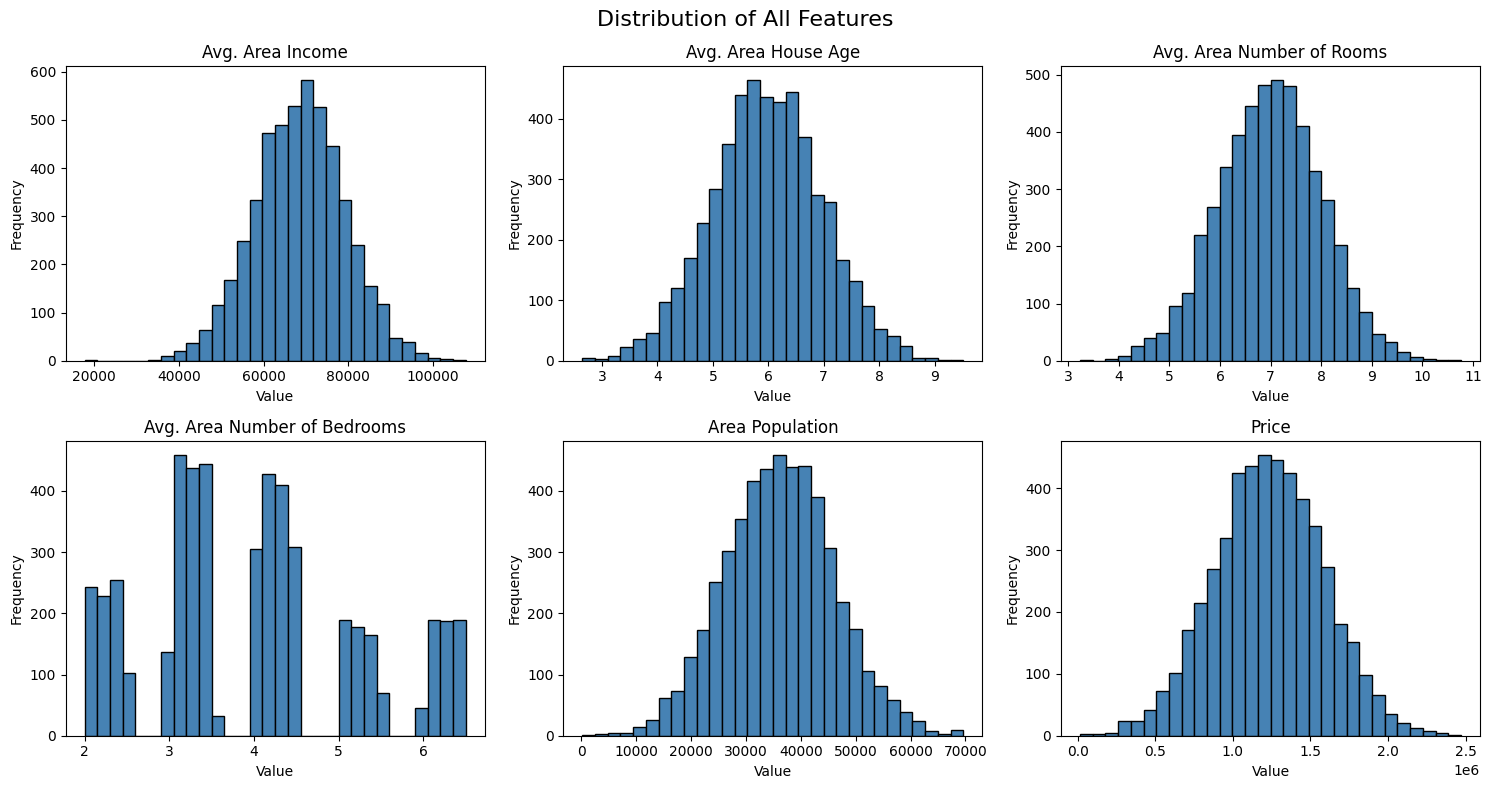

In [6]:
# Distribution of all numerical columns
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

cols = ['Avg. Area Income', 'Avg. Area House Age', 'Avg. Area Number of Rooms',
        'Avg. Area Number of Bedrooms', 'Area Population', 'Price']

for i, col in enumerate(cols):
    axes[i].hist(df[col], bins=30, color='steelblue', edgecolor='black')
    axes[i].set_title(col)
    axes[i].set_xlabel('Value')
    axes[i].set_ylabel('Frequency')

plt.suptitle('Distribution of All Features', fontsize=16)
plt.tight_layout()
plt.show()

### Insight — Univariate Analysis:
All numerical features show an approximately normal distribution
(bell-shaped curve), which is ideal for Linear Regression.
The Price column ranges widely, showing significant variation
in house prices across different areas.
Area Population is slightly right-skewed, meaning most areas
have lower population with a few highly populated areas.

### 5b: Bivariate Analysis — Relationship Between Features and Price

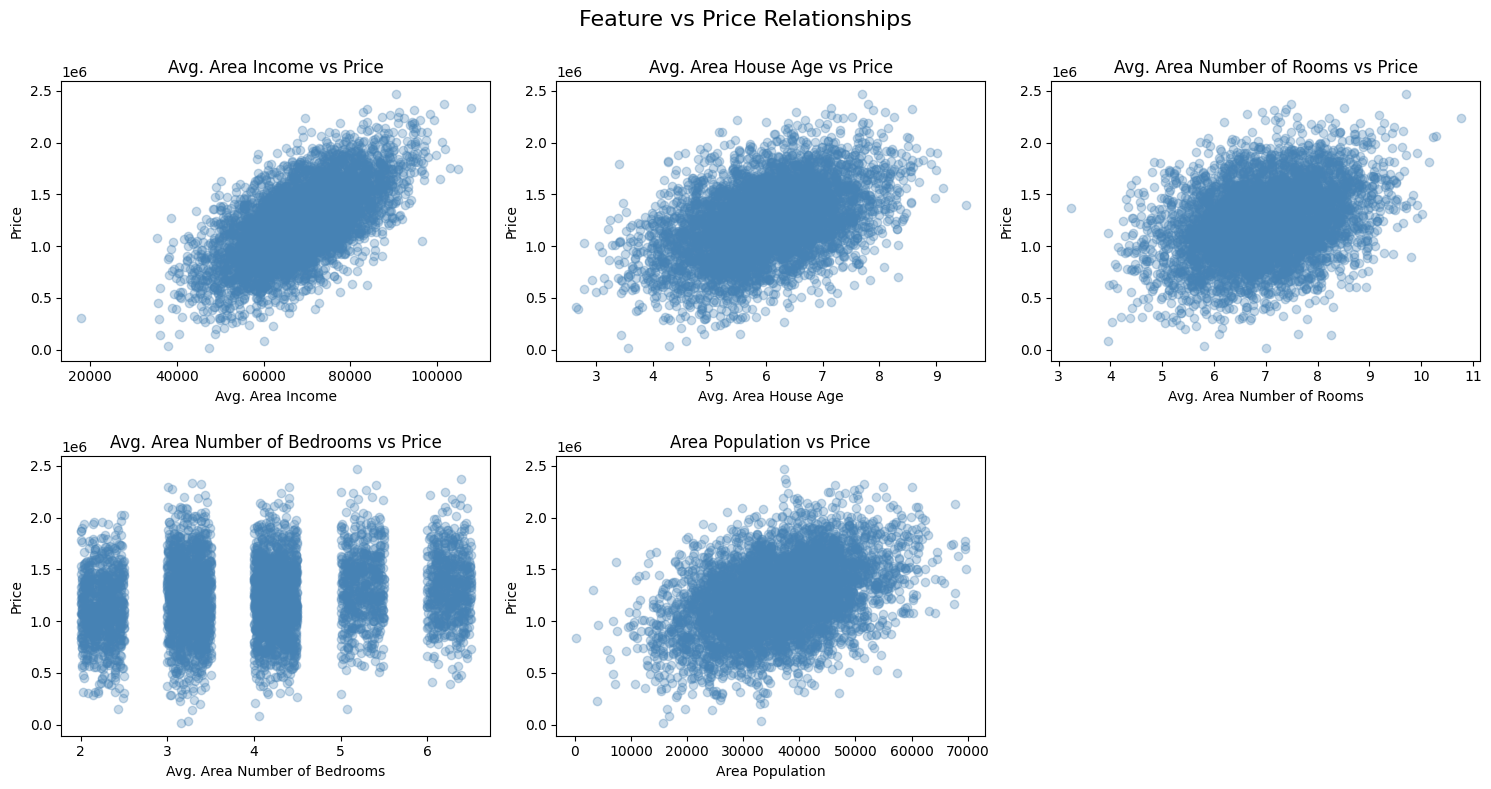

In [8]:
# Scatter plots of each feature vs Price
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

features = ['Avg. Area Income', 'Avg. Area House Age', 'Avg. Area Number of Rooms',
            'Avg. Area Number of Bedrooms', 'Area Population']

for i, col in enumerate(features):
    axes[i].scatter(df[col], df['Price'], alpha=0.3, color='steelblue')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Price')
    axes[i].set_title(f'{col} vs Price')

axes[5].axis('off')  # hide the empty 6th plot
plt.suptitle('Feature vs Price Relationships', fontsize=16)
plt.tight_layout()
plt.show()

### Insight — Bivariate Analysis:
Avg. Area Income shows the strongest positive relationship with Price —
higher income areas consistently have higher house prices.
Avg. Area House Age and Number of Rooms also show positive relationships.
Avg. Area Number of Bedrooms shows a weak relationship with Price.
Area Population shows the weakest relationship with Price.

### 5c: Correlation Analysis

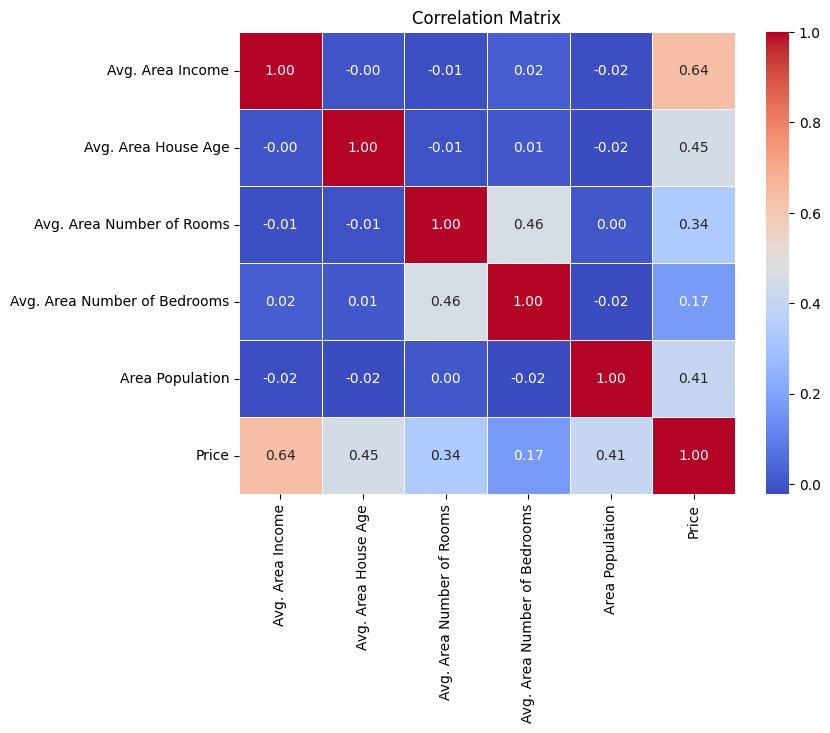

In [9]:
# Correlation heatmap
plt.figure(figsize=(8, 6))
correlation = df.corr()
sns.heatmap(correlation, annot=True, fmt='.2f',
            cmap='coolwarm', linewidths=0.5)
plt.title('Correlation Matrix')
plt.show()

### Insight — Correlation Analysis:
Avg. Area Income has the strongest positive correlation
with Price (0.64), making it the most important predictor.
Avg. Area House Age (0.45) and Area Population (0.41)
show moderate correlations with Price.
Avg. Area Number of Bedrooms has the weakest correlation
with Price (0.17).
No multicollinearity issues exist between input features,
which is good for Linear Regression.

## Task 6: Data Preprocessing

In [10]:
from sklearn.model_selection import train_test_split

X = df.drop('Price', axis=1)
y = df['Price']

xtrain, xtest, ytrain, ytest = train_test_split(
                        X, y, test_size=0.2, random_state=42)

print("Training size:", xtrain.shape)
print("Testing size:", xtest.shape)

Training size: (4000, 5)
Testing size: (1000, 5)


### Insight — Task 6:
The dataset was split into 80% training (4000 rows) and
20% testing (1000 rows) using random_state=42 for
reproducibility. All 5 numerical features are used as
input. Price is the target variable.

## Task 7: Model Building

In [11]:
from sklearn.linear_model import LinearRegression

# Create and train the model
model = LinearRegression()
model.fit(xtrain, ytrain)

print("Model trained successfully!")
print("\nModel Coefficients:")
for col, coef in zip(X.columns, model.coef_):
    print(f"  {col}: {coef:.2f}")
print(f"\nIntercept: {model.intercept_:.2f}")

Model trained successfully!

Model Coefficients:
  Avg. Area Income: 21.65
  Avg. Area House Age: 164666.48
  Avg. Area Number of Rooms: 119624.01
  Avg. Area Number of Bedrooms: 2440.38
  Area Population: 15.27

Intercept: -2635072.90


### Insight — Task 7:
The Linear Regression model was trained successfully.
Avg. Area House Age has the highest coefficient (164666),
meaning house age impacts price the most per unit change.
Avg. Area Income has the lowest per-unit coefficient (21.65)
but impacts price most overall due to its wide range of values.
Area Population has the smallest effect on price (15.27).

## Task 8: Model Evaluation

In [12]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Make predictions
ypred = model.predict(xtest)

# Calculate metrics
r2  = r2_score(ytest, ypred)
mae = mean_absolute_error(ytest, ypred)
mse = mean_squared_error(ytest, ypred)
rmse = np.sqrt(mse)

print(f"R² Score:  {r2:.4f}")
print(f"MAE:       {mae:.2f}")
print(f"MSE:       {mse:.2f}")
print(f"RMSE:      {rmse:.2f}")

R² Score:  0.9180
MAE:       80879.10
MSE:       10089009300.89
RMSE:      100444.06


### Insight - Task 8:
The model achieved an R2 score of 0.9180, meaning it explains
91.8% of the variation in house prices - excellent performance!
The MAE of 80,879 means predictions are off by around 80K on average.
The RMSE of 100,444 is acceptable given house prices range
from 500K to 2.5M in this dataset.
Overall the Linear Regression model fits this dataset very well.

## Task 9: Result Interpretation

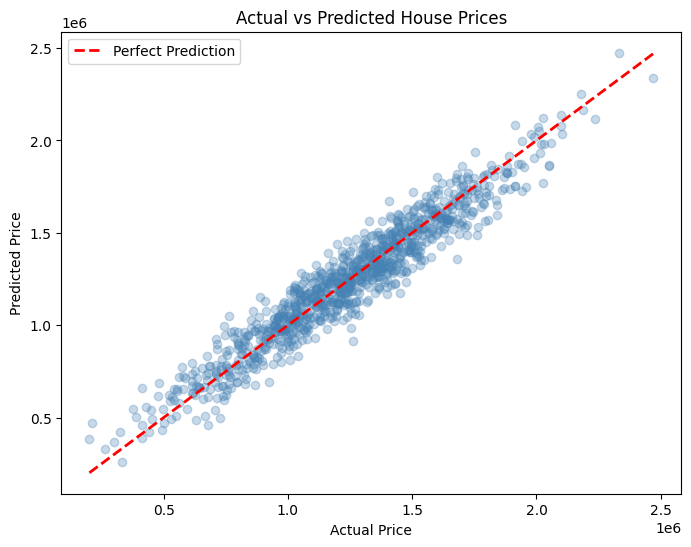

In [13]:
# Actual vs Predicted plot
plt.figure(figsize=(8, 6))
plt.scatter(ytest, ypred, alpha=0.3, color='steelblue')
plt.plot([ytest.min(), ytest.max()],
         [ytest.min(), ytest.max()],
         'r--', linewidth=2, label='Perfect Prediction')
plt.xlabel('Actual Price')
plt.ylabel('Predicted Price')
plt.title('Actual vs Predicted House Prices')
plt.legend()
plt.show()

### Insight - Task 9:
The Actual vs Predicted plot shows that most predictions
closely follow the perfect prediction line, confirming the
model performs well across all price ranges.
The model slightly underestimates some very high-priced houses
but overall the predictions are reliable and consistent.
Linear Regression is a suitable model for this dataset.

## Task 10: Final Conclusion

### Summary of Findings:
In this project, a Linear Regression model was built to
predict USA house prices using the USA_Housing dataset.

Key findings from EDA:
- Avg. Area Income is the strongest predictor of house price (correlation 0.64)
- All features show positive relationships with Price
- No missing values were found - the dataset was clean

Model Performance:
- R2 Score: 0.9180 - the model explains 91.8% of price variation
- MAE: 80,879 - average prediction error is around 80K
- RMSE: 100,444

Conclusion:
Linear Regression is an excellent fit for this dataset.
The model successfully learned the relationship between
house features and prices with high accuracy.